In [7]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [6]:
#define state
class BMI(TypedDict):
    height: float  # in meters
    weight: float  # in kilograms
    bmi: float     # Body Mass Index

In [13]:
def bmi_cal(state: BMI) -> BMI:
    height = state['height']
    weight = state['weight']

    bmi = weight/(height**2)

    state['bmi'] = round(bmi, 2)

    return state

In [14]:
#initialize graph
graph = StateGraph(BMI)

#add nodes 
graph.add_node('bmi_cal', bmi_cal)

#add edges
graph.add_edge(START, 'bmi_cal')
graph.add_edge('bmi_cal', END)

#compile graph
workflow = graph.compile()

In [15]:
#excecute graph
initial_state = {'height':1.73, 'weight': 80}

final_state = workflow.invoke(initial_state)

print(final_state)

{'height': 1.73, 'weight': 80, 'bmi': 26.73}


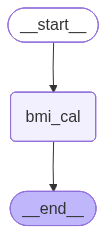

In [ ]:
#visualizing graph
from IPython.display import Image

Image(workflow.get_graph().draw_mermaid_png())
